# Exercise 47 – Finding a low-energy Lennard-Jones-Gauss cluster

**Week 8 · Automatic differentiation**

The total energy of a 12-atom 2D cluster is the sum of the
Lennard-Jones-Gauss pair potential over all pairs. Treating the atomic
positions as parameters, gradient descent relaxes a cluster to the nearest
local minimum. Because the energy landscape has many minima, we restart from
several random configurations and keep the best result (a simple
*multi-start* global optimisation).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch

from comphy.clusters import plot_cluster, random_positions
from comphy.plotting import setup_axes
from comphy.potentials import LennardJonesGauss

calc = LennardJonesGauss(eps=1, sigma_squared=0.02, r0=1.7)

## Energy of a given cluster

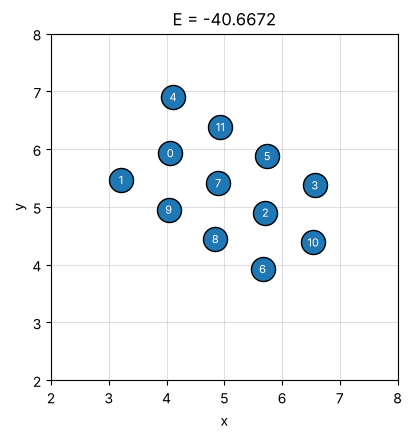

In [2]:
given = torch.tensor([[4.065, 5.930], [3.211, 5.465], [5.711, 4.900], [6.567, 5.374],
                      [4.113, 6.903], [5.741, 5.879], [5.662, 3.924], [4.893, 5.411],
                      [4.844, 4.443], [4.036, 4.953], [6.539, 4.384], [4.931, 6.382]])

fig, ax = plt.subplots(figsize=(4.5, 4.5))
plot_cluster(ax, given)
setup_axes(ax, xlim=(2, 8), ylim=(2, 8), zero_lines=False, equal=True,
           title=f"E = {calc(given).item():.4f}")
plt.show()

## Relaxing random clusters

Random starting positions can put two atoms almost on top of each other,
where the $1/r^{12}$ term gives enormous gradients. Clipping the gradient
norm keeps the first steps stable.

In [3]:
def relax(positions, steps=3000, lr=0.01, max_grad=1.0):
    pos = torch.tensor(positions, dtype=torch.float32, requires_grad=True)
    optimizer = torch.optim.Adam([pos], lr=lr)
    for _ in range(steps):
        optimizer.zero_grad()
        energy = calc(pos)
        energy.backward()
        torch.nn.utils.clip_grad_norm_([pos], max_grad)
        optimizer.step()
    return pos.detach(), calc(pos).item()


rng = np.random.default_rng(0)
results = []
for trial in range(20):
    start = random_positions(12, box_width=5, rng=rng)
    relaxed, energy = relax(start)
    results.append((energy, start, relaxed))

energies = np.array([r[0] for r in results])
print("Energies of the 20 relaxed clusters:")
print(np.sort(energies).round(3))

Energies of the 20 relaxed clusters:
[-34.908 -33.389 -32.618 -32.601 -31.397 -30.797 -29.904 -29.588 -29.397
 -29.204 -27.404 -27.2   -26.825 -26.822 -26.002 -25.943 -25.507 -25.45
 -25.143 -23.344]


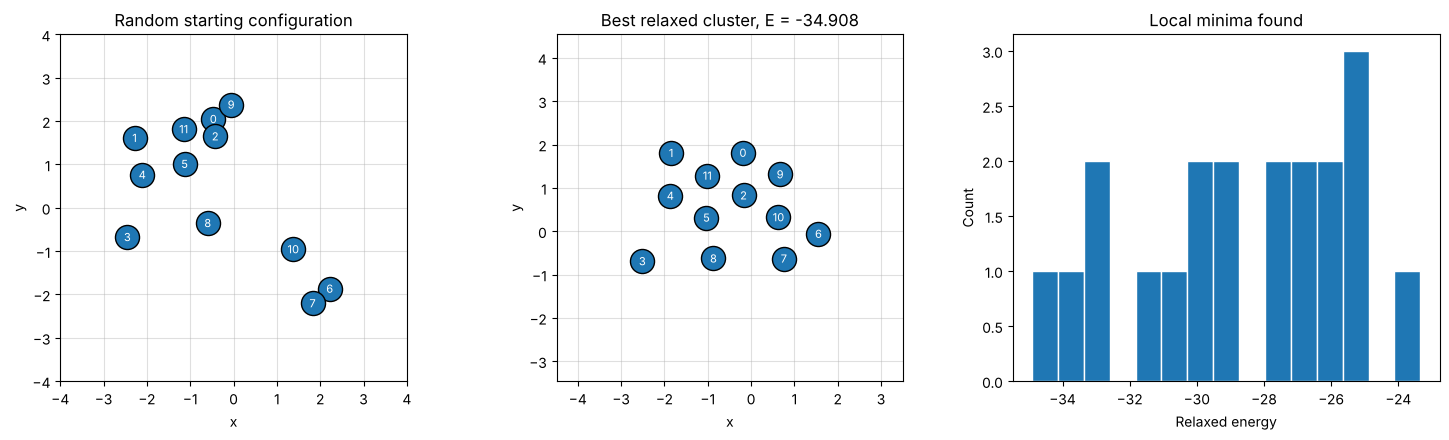

In [4]:
best_energy, best_start, best = min(results, key=lambda r: r[0])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
plot_cluster(axes[0], best_start)
setup_axes(axes[0], xlim=(-4, 4), ylim=(-4, 4), title="Random starting configuration",
           zero_lines=False, equal=True)
plot_cluster(axes[1], best)
centre = best.mean(dim=0).numpy()
setup_axes(axes[1], xlim=(centre[0] - 4, centre[0] + 4), ylim=(centre[1] - 4, centre[1] + 4),
           title=f"Best relaxed cluster, E = {best_energy:.3f}", zero_lines=False, equal=True)
axes[2].hist(energies, bins=15, color="C0", edgecolor="white")
axes[2].set(xlabel="Relaxed energy", ylabel="Count", title="Local minima found")
fig.tight_layout()
plt.show()